## Benchmark Setup & Imports

In [1]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from ultralytics import FastSAM, SAM, YOLO

# 1. Device Setup
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")

# 2. Path Definitions (Self-contained to avoid undefined variable errors)
PROJECT_ROOT = os.path.abspath("..")
IMAGE_DIR = os.path.join(PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs", "seg_results")
EXCEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "experiment_results.xlsx")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 3. Load Sample Images
sample_images = [
    f
    for f in os.listdir(IMAGE_DIR)
    if f.endswith(".jpg") or f.endswith(".png")
][:3]
print(f"Loaded {len(sample_images)} test images from: {IMAGE_DIR}")

# 4. 10 Robust Models List
models_to_test = [
    {"name": "YOLOv8-Nano", "weights": "yolov8n-seg.pt", "type": "yolo"},
    {"name": "YOLOv8-Small", "weights": "yolov8s-seg.pt", "type": "yolo"},
    {"name": "YOLOv8-Medium", "weights": "yolov8m-seg.pt", "type": "yolo"},
    {"name": "YOLOv9-Compact", "weights": "yolov9c-seg.pt", "type": "yolo"},
    {"name": "YOLOv9-Extended", "weights": "yolov9e-seg.pt", "type": "yolo"},
    {"name": "YOLOv11-Nano", "weights": "yolo11n-seg.pt", "type": "yolo"},
    {"name": "YOLOv11-Small", "weights": "yolo11s-seg.pt", "type": "yolo"},
    {"name": "YOLOv11-Medium", "weights": "yolo11m-seg.pt", "type": "yolo"},
    {"name": "FastSAM-Small", "weights": "FastSAM-s.pt", "type": "fastsam"},
    {"name": "SAM2-Tiny", "weights": "sam2_t.pt", "type": "sam"},
]

results_list = []

# 5. Benchmark Loop
for model_cfg in models_to_test:
    model_name = model_cfg["name"]
    weights = model_cfg["weights"]
    model_type = model_cfg["type"]

    print(f"\n--- Testing Model: {model_name} ({weights}) ---")

    try:
        # Load correct class architecture
        if model_type == "fastsam":
            model = FastSAM(weights)
        elif model_type == "sam":
            model = SAM(weights)
        else:
            model = YOLO(weights)

        total_time = 0
        total_objects = 0

        # Warmup pass on MPS
        _ = model.predict(
            source=os.path.join(IMAGE_DIR, sample_images[0]),
            device=device,
            verbose=False,
        )

        for img_name in sample_images:
            img_path = os.path.join(IMAGE_DIR, img_name)

            start = time.time()
            res = model.predict(source=img_path, device=device, verbose=False)
            latency = (time.time() - start) * 1000

            total_time += latency

            if res[0].boxes is not None:
                total_objects += len(res[0].boxes)

            if img_name == sample_images[0]:
                plotted_img = res[0].plot()
                save_path = os.path.join(
                    OUTPUT_DIR, f"{model_name}_{img_name}"
                )
                cv2.imwrite(save_path, plotted_img)

        avg_latency = round(total_time / len(sample_images), 2)
        avg_fps = round(1000 / avg_latency, 2)
        avg_objects = round(total_objects / len(sample_images), 1)

        print(
            f"Success: {avg_latency} ms/frame | {avg_fps} FPS | Avg Detections: {avg_objects}"
        )

        results_list.append({
            "Exp_ID": f"EXP_SEG_{int(time.time())}",
            "Timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
            "Task": "Segmentation Comparison",
            "Model": model_name,
            "Weights": weights,
            "Avg_Latency_ms": avg_latency,
            "Avg_FPS": avg_fps,
            "Avg_Detections": avg_objects,
            "Device": str(device),
        })

    except Exception as e:
        print(f"Error testing {model_name}: {e}")

# 6. Save results to Excel
if results_list:
    df_benchmark = pd.DataFrame(results_list)

    if os.path.exists(EXCEL_PATH):
        df_existing = pd.read_excel(EXCEL_PATH)
        df_final = pd.concat([df_existing, df_benchmark], ignore_index=True)
    else:
        df_final = df_benchmark

    df_final.to_excel(EXCEL_PATH, index=False)
    print(f"\nAll benchmark results logged to {EXCEL_PATH}")

    # Display results table directly in notebook output
    display(
        df_benchmark.sort_values(
            by="Avg_FPS", ascending=False
        ).reset_index(drop=True)
    )

Device: mps
Loaded 3 test images from: /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/v1.0-mini/samples/CAM_FRONT

--- Testing Model: YOLOv8-Nano (yolov8n-seg.pt) ---
Success: 74.63 ms/frame | 13.4 FPS | Avg Detections: 8.7

--- Testing Model: YOLOv8-Small (yolov8s-seg.pt) ---
Success: 53.09 ms/frame | 18.84 FPS | Avg Detections: 12.7

--- Testing Model: YOLOv8-Medium (yolov8m-seg.pt) ---
Success: 60.58 ms/frame | 16.51 FPS | Avg Detections: 12.3

--- Testing Model: YOLOv9-Compact (yolov9c-seg.pt) ---
Success: 78.69 ms/frame | 12.71 FPS | Avg Detections: 12.7

--- Testing Model: YOLOv9-Extended (yolov9e-seg.pt) ---
Success: 132.0 ms/frame | 7.58 FPS | Avg Detections: 12.7

--- Testing Model: YOLOv11-Nano (yolo11n-seg.pt) ---
Success: 21.1 ms/frame | 47.39 FPS | Avg Detections: 8.7

--- Testing Model: YOLOv11-Small (yolo11s-seg.pt) ---
Success: 34.01 ms/frame | 29.4 FPS | Avg Detections: 11.0

--- Testing Model: YOLOv11-Medium (yolo11m-seg.pt) ---
Success: 70.61 ms/fra

,Exp_ID,Timestamp,Task,Model,Weights,Avg_Latency_ms,Avg_FPS,Avg_Detections,Device
0,EXP_SEG_1788670617,2026-09-06 10:26:57,Segmentation Comparison,YOLOv11-Nano,yolo11n-seg.pt,21.10,47.39,8.7,mps
1,EXP_SEG_1788670617,2026-09-06 10:26:57,Segmentation Comparison,YOLOv11-Small,yolo11s-seg.pt,34.01,29.40,11.0,mps
2,EXP_SEG_1788670614,2026-09-06 10:26:54,Segmentation Comparison,YOLOv8-Small,yolov8s-seg.pt,53.09,18.84,12.7,mps
3,EXP_SEG_1788670614,2026-09-06 10:26:54,Segmentation Comparison,YOLOv8-Medium,yolov8m-seg.pt,60.58,16.51,12.3,mps
4,EXP_SEG_1788670618,2026-09-06 10:26:58,Segmentation Comparison,YOLOv11-Medium,yolo11m-seg.pt,70.61,14.16,12.3,mps
5,EXP_SEG_1788670613,2026-09-06 10:26:53,Segmentation Comparison,YOLOv8-Nano,yolov8n-seg.pt,74.63,13.40,8.7,mps
6,EXP_SEG_1788670615,2026-09-06 10:26:55,Segmentation Comparison,YOLOv9-Compact,yolov9c-seg.pt,78.69,12.71,12.7,mps
7,EXP_SEG_1788670616,2026-09-06 10:26:56,Segmentation Comparison,YOLOv9-Extended,yolov9e-seg.pt,132.00,7.58,12.7,mps
8,EXP_SEG_1788670619,2026-09-06 10:26:59,Segmentation Comparison,FastSAM-Small,FastSAM-s.pt,242.52,4.12,77.3,mps
9,EXP_SEG_1788670683,2026-09-06 10:28:03,Segmentation Comparison,SAM2-Tiny,sam2_t.pt,15716.92,0.06,13.0,mps


## Comparative Analysis & Automated Logging to Excel

In [2]:
# Create summary dataframe
df_benchmark = pd.DataFrame(results_list)

# Save/Append to central Excel Sheet
if os.path.exists(EXCEL_PATH):
    df_existing = pd.read_excel(EXCEL_PATH)
    df_final = pd.concat([df_existing, df_benchmark], ignore_index=True)
else:
    df_final = df_benchmark

df_final.to_excel(EXCEL_PATH, index=False)
print(f"Successfully appended 10-model comparison data to {EXCEL_PATH}")

# Display Comparative Table directly in notebook
df_benchmark.sort_values(by="Avg_FPS", ascending=False)

Successfully appended 10-model comparison data to /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/notebooks/experiment_results.xlsx


,Exp_ID,Timestamp,Task,Model,Weights,Avg_Latency_ms,Avg_FPS,Avg_Detections,Device
5,EXP_SEG_1788670617,2026-09-06 10:26:57,Segmentation Comparison,YOLOv11-Nano,yolo11n-seg.pt,21.10,47.39,8.7,mps
6,EXP_SEG_1788670617,2026-09-06 10:26:57,Segmentation Comparison,YOLOv11-Small,yolo11s-seg.pt,34.01,29.40,11.0,mps
1,EXP_SEG_1788670614,2026-09-06 10:26:54,Segmentation Comparison,YOLOv8-Small,yolov8s-seg.pt,53.09,18.84,12.7,mps
2,EXP_SEG_1788670614,2026-09-06 10:26:54,Segmentation Comparison,YOLOv8-Medium,yolov8m-seg.pt,60.58,16.51,12.3,mps
7,EXP_SEG_1788670618,2026-09-06 10:26:58,Segmentation Comparison,YOLOv11-Medium,yolo11m-seg.pt,70.61,14.16,12.3,mps
0,EXP_SEG_1788670613,2026-09-06 10:26:53,Segmentation Comparison,YOLOv8-Nano,yolov8n-seg.pt,74.63,13.40,8.7,mps
3,EXP_SEG_1788670615,2026-09-06 10:26:55,Segmentation Comparison,YOLOv9-Compact,yolov9c-seg.pt,78.69,12.71,12.7,mps
4,EXP_SEG_1788670616,2026-09-06 10:26:56,Segmentation Comparison,YOLOv9-Extended,yolov9e-seg.pt,132.00,7.58,12.7,mps
8,EXP_SEG_1788670619,2026-09-06 10:26:59,Segmentation Comparison,FastSAM-Small,FastSAM-s.pt,242.52,4.12,77.3,mps
9,EXP_SEG_1788670683,2026-09-06 10:28:03,Segmentation Comparison,SAM2-Tiny,sam2_t.pt,15716.92,0.06,13.0,mps


## Plot Visual Performance Graph in Notebook Output

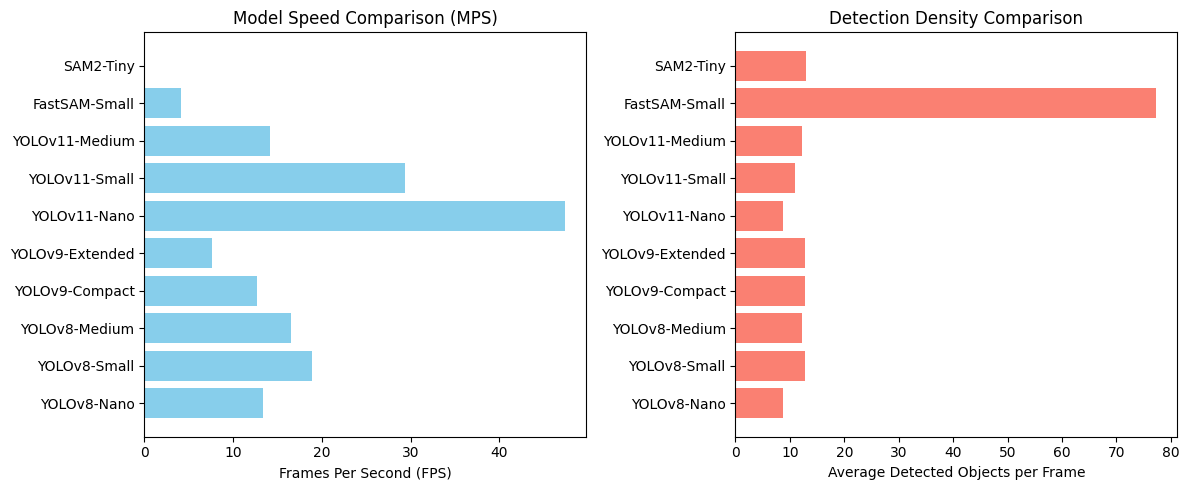

In [3]:
# Visualizing Speed (FPS) vs Detection Count across models
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.barh(
    df_benchmark["Model"], df_benchmark["Avg_FPS"], color="skyblue"
)
plt.xlabel("Frames Per Second (FPS)")
plt.title("Model Speed Comparison (MPS)")

plt.subplot(1, 2, 2)
plt.barh(
    df_benchmark["Model"],
    df_benchmark["Avg_Detections"],
    color="salmon",
)
plt.xlabel("Average Detected Objects per Frame")
plt.title("Detection Density Comparison")

plt.tight_layout()
plt.show()